# Exploratory data analysis

Explores the pipeline's tables: coverage of each source, release and commit activity,
label prevalence, feature missingness, how features differ between abandoned and active
packages, and the dependency graph over time.

Set `DATA_DIR` to the repository root of a pipeline run (default: the current repo). The
committed outputs were produced on the **pilot** profile (500 top packages plus their
dependencies); every number below comes from that run.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from pypirisk.io import read_table

ROOT = Path(os.environ.get("DATA_DIR", ".."))
validated = ROOT / "data" / "validated"
packages = read_table(validated, "packages")
releases = read_table(validated, "releases")
commits = read_table(validated, "commits")
issues = read_table(validated, "issues")
features = pd.read_parquet(ROOT / "data" / "features" / "features.parquet")
labels = pd.read_parquet(ROOT / "data" / "labels" / "labels.parquet")
nodes = pd.read_parquet(ROOT / "data" / "graph" / "nodes.parquet")
ingest = json.loads((ROOT / "reports" / "ingest.json").read_text())
print(f"profile: {ingest['profile']}")
{
    name: len(table)
    for name, table in [
        ("packages", packages),
        ("releases", releases),
        ("commits", commits),
        ("issues", issues),
    ]
}

profile: pilot


{'packages': 698, 'releases': 63376, 'commits': 1256275, 'issues': 755196}

## 1. Source coverage

Share of packages each source covers, and where repositories are hosted.

In [2]:
pd.Series(ingest["coverage"]).to_frame("value")

,value
packages,698.0000
seed_packages,500.0000
share_archived,0.0301
share_monorepo,0.1160
share_with_commits,0.9183
share_with_issues,0.9054
share_with_repository,0.9241


In [3]:
packages["repo_host"].fillna("no repository link").value_counts().to_frame("packages")

,packages
repo_host,
github.com,637
no repository link,53
codeberg.org,4
bitbucket.org,3
gitlab.com,1


In [4]:
pd.Series(ingest["crawl"]["errors_by_source"], dtype=int).to_frame("errors")

,errors
ecosystems_issues,5
git,4


## 2. Activity at the scoring snapshot

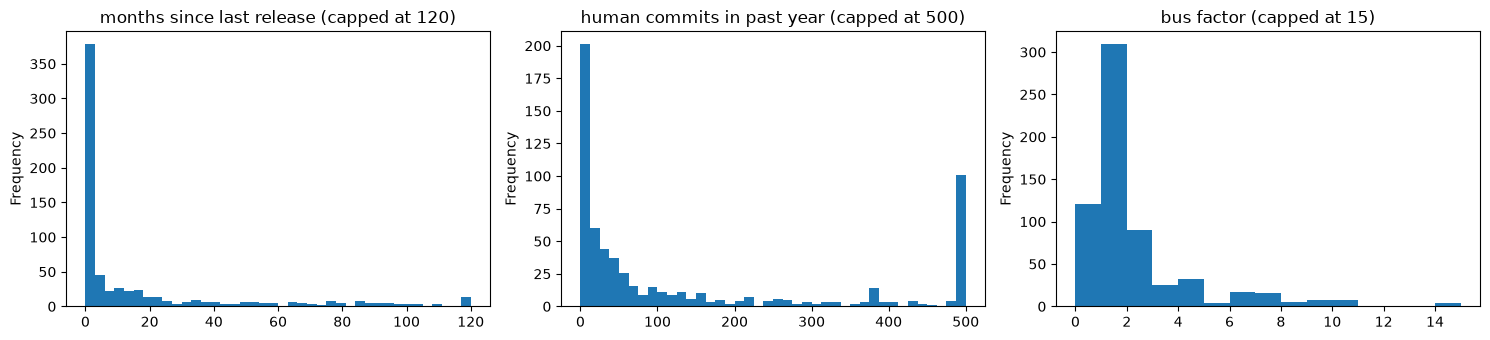

In [5]:
scoring = features[features["snapshot"] == features["snapshot"].max()]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
scoring["months_since_last_release"].clip(upper=120).plot.hist(
    bins=40, ax=axes[0], title="months since last release (capped at 120)"
)
scoring["commits_in_lookback"].clip(upper=500).plot.hist(
    bins=40, ax=axes[1], title="human commits in past year (capped at 500)"
)
scoring["bus_factor"].clip(upper=15).plot.hist(
    bins=15, ax=axes[2], title="bus factor (capped at 15)"
)
plt.tight_layout()

In [6]:
scoring[
    [
        "releases_in_lookback",
        "months_since_last_release",
        "commits_in_lookback",
        "bus_factor",
        "top_author_share",
        "median_days_to_close",
    ]
].describe().round(2)

,releases_in_lookback,months_since_last_release,commits_in_lookback,bus_factor,top_author_share,median_days_to_close
count,698.00,698.00,641.00,641.00,641.00,472.00
mean,11.27,18.48,378.51,1.92,0.47,220.64
std,31.78,32.11,1419.20,2.77,0.34,479.94
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.37,5.00,1.00,0.16,3.99
50%,2.50,2.29,42.00,1.00,0.47,32.39
75%,9.00,18.26,252.00,2.00,0.75,199.97
max,409.00,196.15,26426.00,38.00,1.00,4165.76


## 3. Labels

Eligible packages per snapshot and the share abandoned within 18 months.

In [7]:
summary = labels.groupby(["split", "snapshot"]).agg(
    eligible=("label", "size"), abandoned=("label", "sum"), prevalence=("label", "mean")
)
summary.round(3)

eligible  abandoned  prevalence
split      snapshot                                   
test       2025-01-01       465         17       0.037
train      2018-01-01       356         14       0.039
           2019-01-01       370         18       0.049
           2020-01-01       393         23       0.059
           2021-01-01       434         24       0.055
validation 2023-01-01       464         23       0.050

In [8]:
labels["label_basis"].value_counts().to_frame("rows")

,rows
label_basis,
releases_and_commits,2364
releases_only,118


The number of eligible packages rises with each snapshot. Part of that is real growth,
but part is **survivorship bias**: the universe is today's top packages, so packages
that were popular in 2018 and later died are under-represented in early snapshots.
The next cell shows how many of today's packages did not exist yet at each snapshot.

In [9]:
first_release = releases.groupby("name")["uploaded_at"].min()
pd.Series(
    {
        s: float((first_release >= pd.Timestamp(s, tz="UTC")).mean())
        for s in sorted(features["snapshot"].unique())
    },
    name="share of packages not yet released",
).round(3).to_frame()

,share of packages not yet released
2018-01-01,0.383
2019-01-01,0.319
2020-01-01,0.268
2021-01-01,0.206
2023-01-01,0.105
2025-01-01,0.049
2026-11-01,0.000


## 4. Feature missingness

Missing values are kept as missing (see HLD D15).

In [10]:
columns = [c for c in features.columns if c not in ("name", "snapshot", "repo_url")]
features[columns].isna().mean().sort_values(ascending=False).round(3).to_frame(
    "missing share"
).head(12)

,missing share
median_days_to_close,0.382
open_issue_share,0.270
issues_opened_in_lookback,0.098
issues_closed_in_lookback,0.098
months_since_last_commit,0.089
active_months_in_lookback,0.065
authors_in_lookback,0.065
top_author_share,0.065
bus_factor,0.065
commits_in_lookback,0.065


## 5. Features by outcome (all labelled rows)

In [11]:
data = labels.merge(features, on=["name", "snapshot"])
compare = [
    "months_since_last_release",
    "releases_in_lookback",
    "commits_in_lookback",
    "months_since_last_commit",
    "bus_factor",
    "open_issue_share",
    "dependents",
    "upstream_stale_share",
]
data.groupby("label")[compare].median().T.rename(
    columns={0: "active (median)", 1: "abandoned (median)"}
).round(2)

label,active (median),abandoned (median)
months_since_last_release,1.91,4.83
releases_in_lookback,4.00,1.00
commits_in_lookback,74.00,11.00
months_since_last_commit,0.41,3.27
bus_factor,1.00,1.00
open_issue_share,0.50,0.33
dependents,0.00,1.00
upstream_stale_share,0.00,0.00


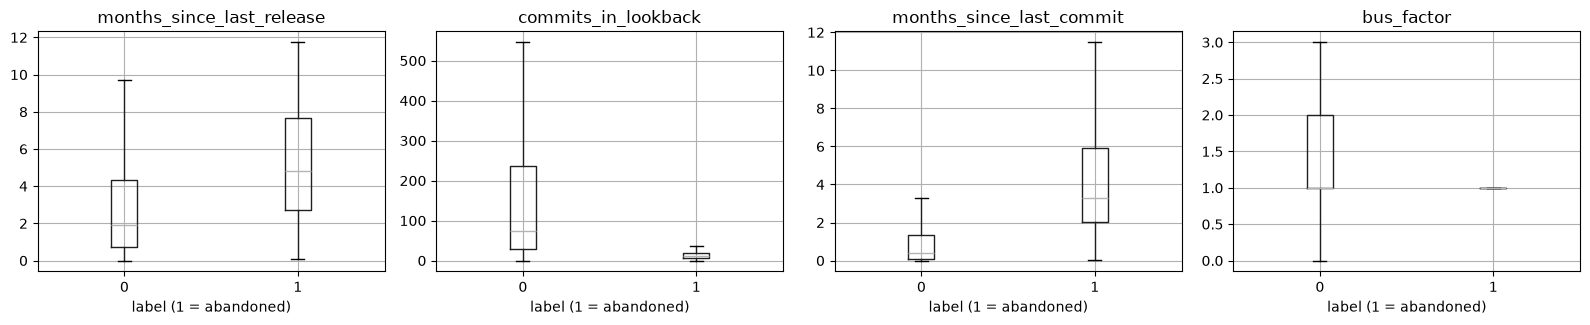

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for axis, column in zip(
    axes,
    ["months_since_last_release", "commits_in_lookback", "months_since_last_commit", "bus_factor"],
    strict=True,
):
    data.boxplot(column=column, by="label", ax=axis, showfliers=False)
    axis.set_title(column)
    axis.set_xlabel("label (1 = abandoned)")
plt.suptitle("")
plt.tight_layout()

## 6. Correlation between features (training rows)

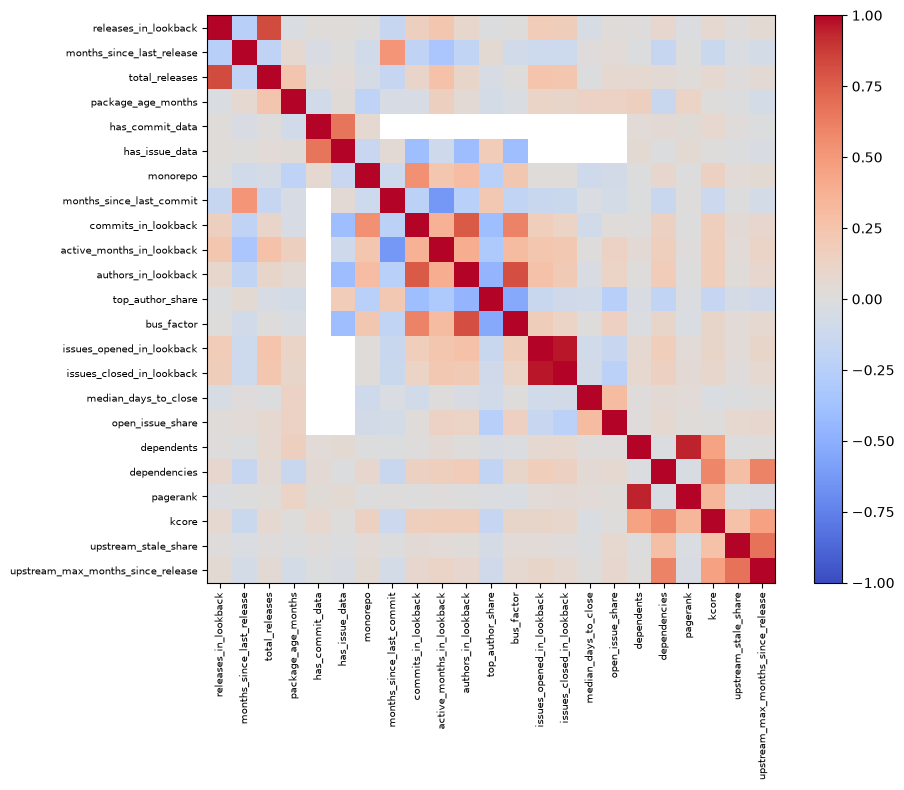

In [13]:
train = data[data["split"] == "train"][columns].astype(float)
corr = train.corr()
fig, axis = plt.subplots(figsize=(10, 8))
image = axis.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
axis.set_yticks(range(len(corr)), corr.columns, fontsize=7)
fig.colorbar(image)
plt.tight_layout()

## 7. Dependency graph over time

In [14]:
graph = nodes.groupby("snapshot").agg(
    packages=("name", "size"), edges=("dependencies", "sum"), max_kcore=("kcore", "max")
)
graph

,packages,edges,max_kcore
snapshot,,,
2018-01-01,431,302,3
2019-01-01,475,447,4
2020-01-01,511,632,5
2021-01-01,554,747,4
2023-01-01,625,902,4
2025-01-01,664,1015,4
2026-11-01,698,1083,4


In [15]:
latest = nodes[nodes["snapshot"] == nodes["snapshot"].max()].nlargest(10, "pagerank")[
    ["name", "dependents", "pagerank", "kcore"]
]
latest.round(2)

,name,dependents,pagerank,kcore
3913,typing-extensions,89,55.22,4
3849,six,13,12.31,3
3807,requests,31,10.48,4
3360,cffi,5,9.08,2
3725,protobuf,14,8.97,4
3741,pycparser,1,8.72,1
3916,tzdata,10,8.44,2
3388,cryptography,15,7.94,4
3680,packaging,30,7.93,4
3923,urllib3,13,7.47,4


## Findings (pilot run, 2026-11-02)

1. **Coverage.** 698 packages (500 seeds plus dependencies); 92.4% link to a repository
   (637 on GitHub), 91.8% have commit history and 90.5% issue history. 53 have no
   repository link. 11.6% share a repository with another package (monorepos).
2. **Labels.** 2,482 labelled rows; prevalence is 3.9% to 5.9% per snapshot (train),
   5.0% in validation and 3.7% in test: a rare-event problem, so PR-AUC and
   precision-at-top matter more than accuracy. 118 rows (4.8%) are labelled on releases
   alone because there is no commit history.
3. **Signal.** Abandoned packages had a median of 11 commits in the year before the
   snapshot against 74 for active ones, 3.3 months since the last commit against 0.4,
   and one release in the year against four.
4. **Missing data.** Issue-closing time is missing for 38% of rows (no issue closed in
   the window) and open-issue share for 27%; activity features are missing for 6.5%
   (no repository). Missing values are kept as missing.
5. **Survivorship bias.** 38% of today's packages did not exist at the 2018 snapshot,
   falling to 5% at 2025. Early snapshots therefore cover a smaller, older population,
   and packages that were popular then but have since died are not in the universe.
6. **Graph.** The dependency graph grows from 302 edges (2018) to 1,083 (2026).
   `typing-extensions`, `six` and `requests` are the most central packages at the scoring
   snapshot.
